- To look at basic QC metrics

- To refine annoations of cell subtypes (based on Azimuth predicted.celltype.l2) by calc DEGs (and check with literature markers), and by mapping from ref CD4 T dataset (because it is more refined)

Found out:
1. Results do not change much re-running Azimuth - it is actually not getting better as it predicts platelets within B cells, indicating that using global reference is not optimal when running within single major cell types. Thus using original Azimuth annotation
2. Re-examine per doublet status - re-ran scrublet-R, and excluded some doublets - it turned out this re-run is not with better results (ie, to distinguish doublet clusters) - b/c previous runs are within single sample and current is within one major cell type across single samples thus affected by batch effect. Thus Thus using original scrublet annotation

# Header

In [1]:
setwd('/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/github')
source('codes/functions.R')

Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built under R 4.4.0 but the current version is
4.4.2; it is recomended that you reinstall ‘SeuratObject’ as the ABI
for R may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t



Attaching package: ‘dplyr’


The following object is masked from ‘package:gridExtra’:

    combine


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘anndata’


The following object is masked from ‘package:SeuratObject’:

    Layers




In [2]:
options(future.globals.maxSize = 120 * 1024 * 1024 * 1024)

In [3]:
packageVersion("Seurat")

[1] ‘5.3.1.0’

# Load

In [4]:
celltype = 'B'

In [5]:
obj = qs::qread(glue("data/03_cleandata/itg_{celltype}.qs"))
obj

An object of class Seurat 
28202 features across 53188 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [6]:
exp.mat <- read.table(
    file = "data/geneset/nestorawa_forcellcycle_expressionMatrix.txt",
    header = TRUE, as.is = TRUE, row.names = 1)

s.genes <- cc.genes$s.genes
g2m.genes <- cc.genes$g2m.genes

In [7]:
obj <- CellCycleScoring(obj, 
                        s.features = s.genes, 
                        g2m.features = g2m.genes, 
                        set.ident = TRUE)


Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”


# Annotate

In [8]:
colnames(obj@meta.data)

[1] "nFeaturess_RNA"              "nFeaturess_RNA_by_counts"   
 [3] "total_counts"                "total_counts_mt"            
 [5] "pct_counts_mt"               "doublets_pred"              
 [7] "doublets_score"              "nCount_RNA"                 
 [9] "nFeature_RNA"                "percent.mt"                 
[11] "predicted.celltype.l1.score" "predicted.celltype.l1"      
[13] "predicted.celltype.l2.score" "predicted.celltype.l2"      
[15] "predicted.celltype.l3.score" "predicted.celltype.l3"      
[17] "mapping.score"               "RNA_snn_res.0.8"            
[19] "seurat_clusters"             "dataset_name"               
[21] "RNA_snn_res.0.1"             "S.Score"                    
[23] "G2M.Score"                   "Phase"                      
[25] "old.ident"

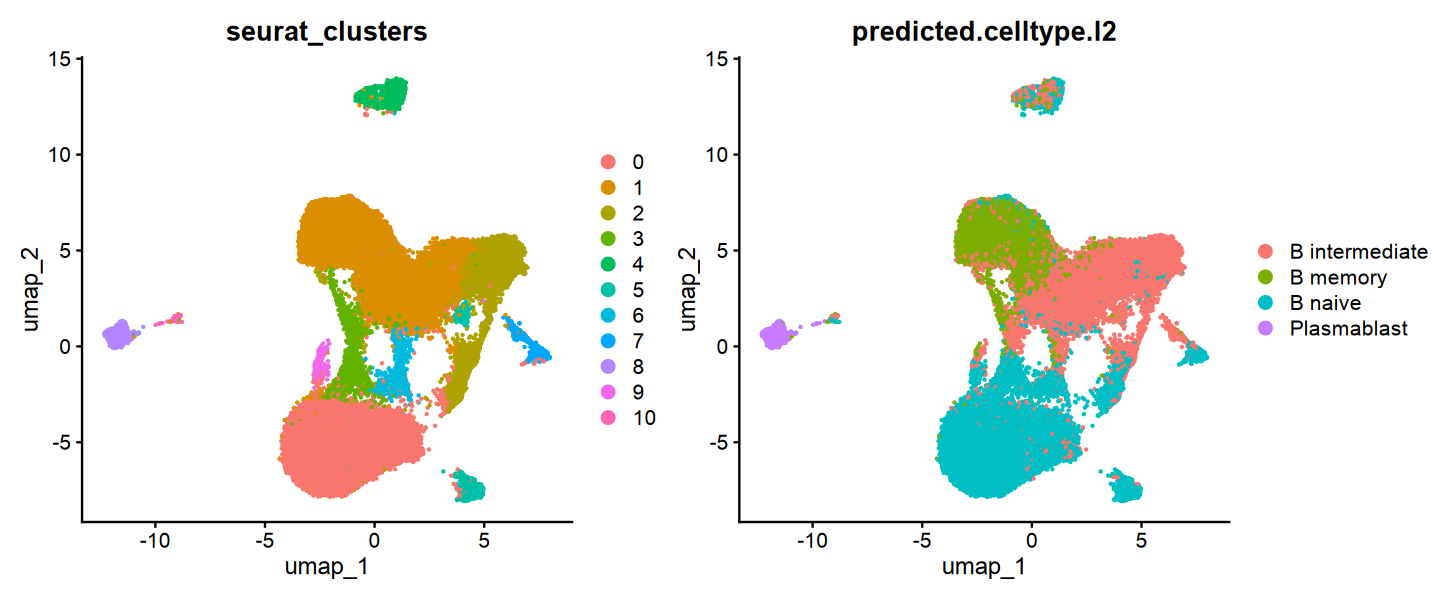

In [25]:
options(repr.plot.width=12, repr.plot.height=5)

DimPlot(obj, reduction = "umap", 
        group.by=c('seurat_clusters','predicted.celltype.l2'),
        ncol=2
       )

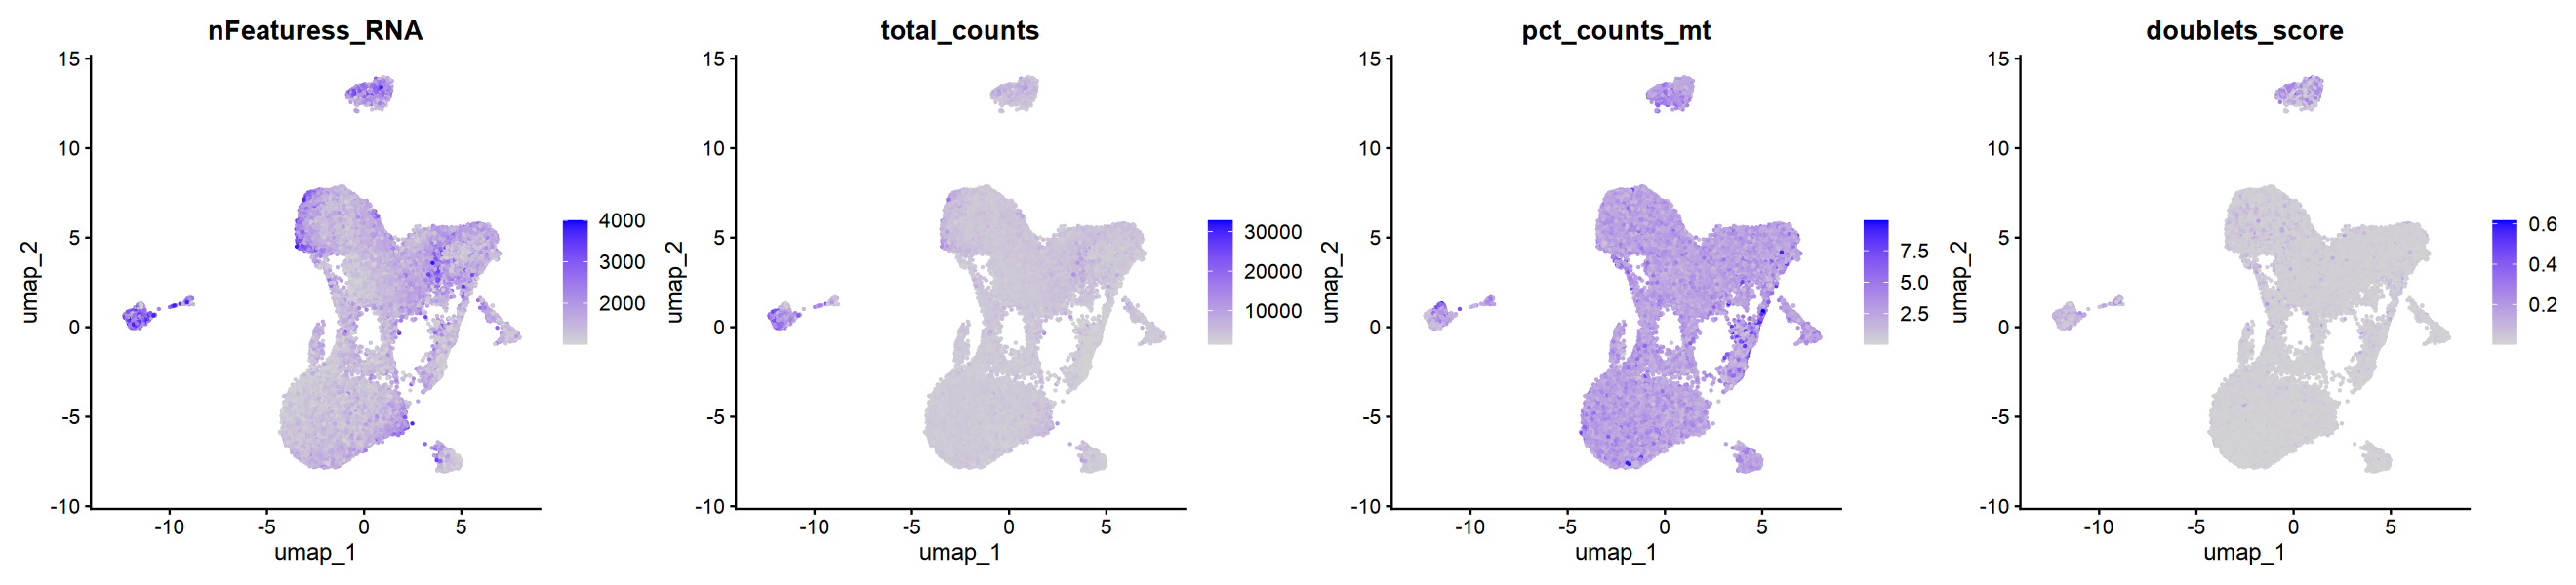

In [9]:
options(repr.plot.width=22, repr.plot.height=5)

FeaturePlot(obj, 
            features = c('nFeaturess_RNA','total_counts','pct_counts_mt','doublets_score'),  
            reduction = 'umap', ncol=4)

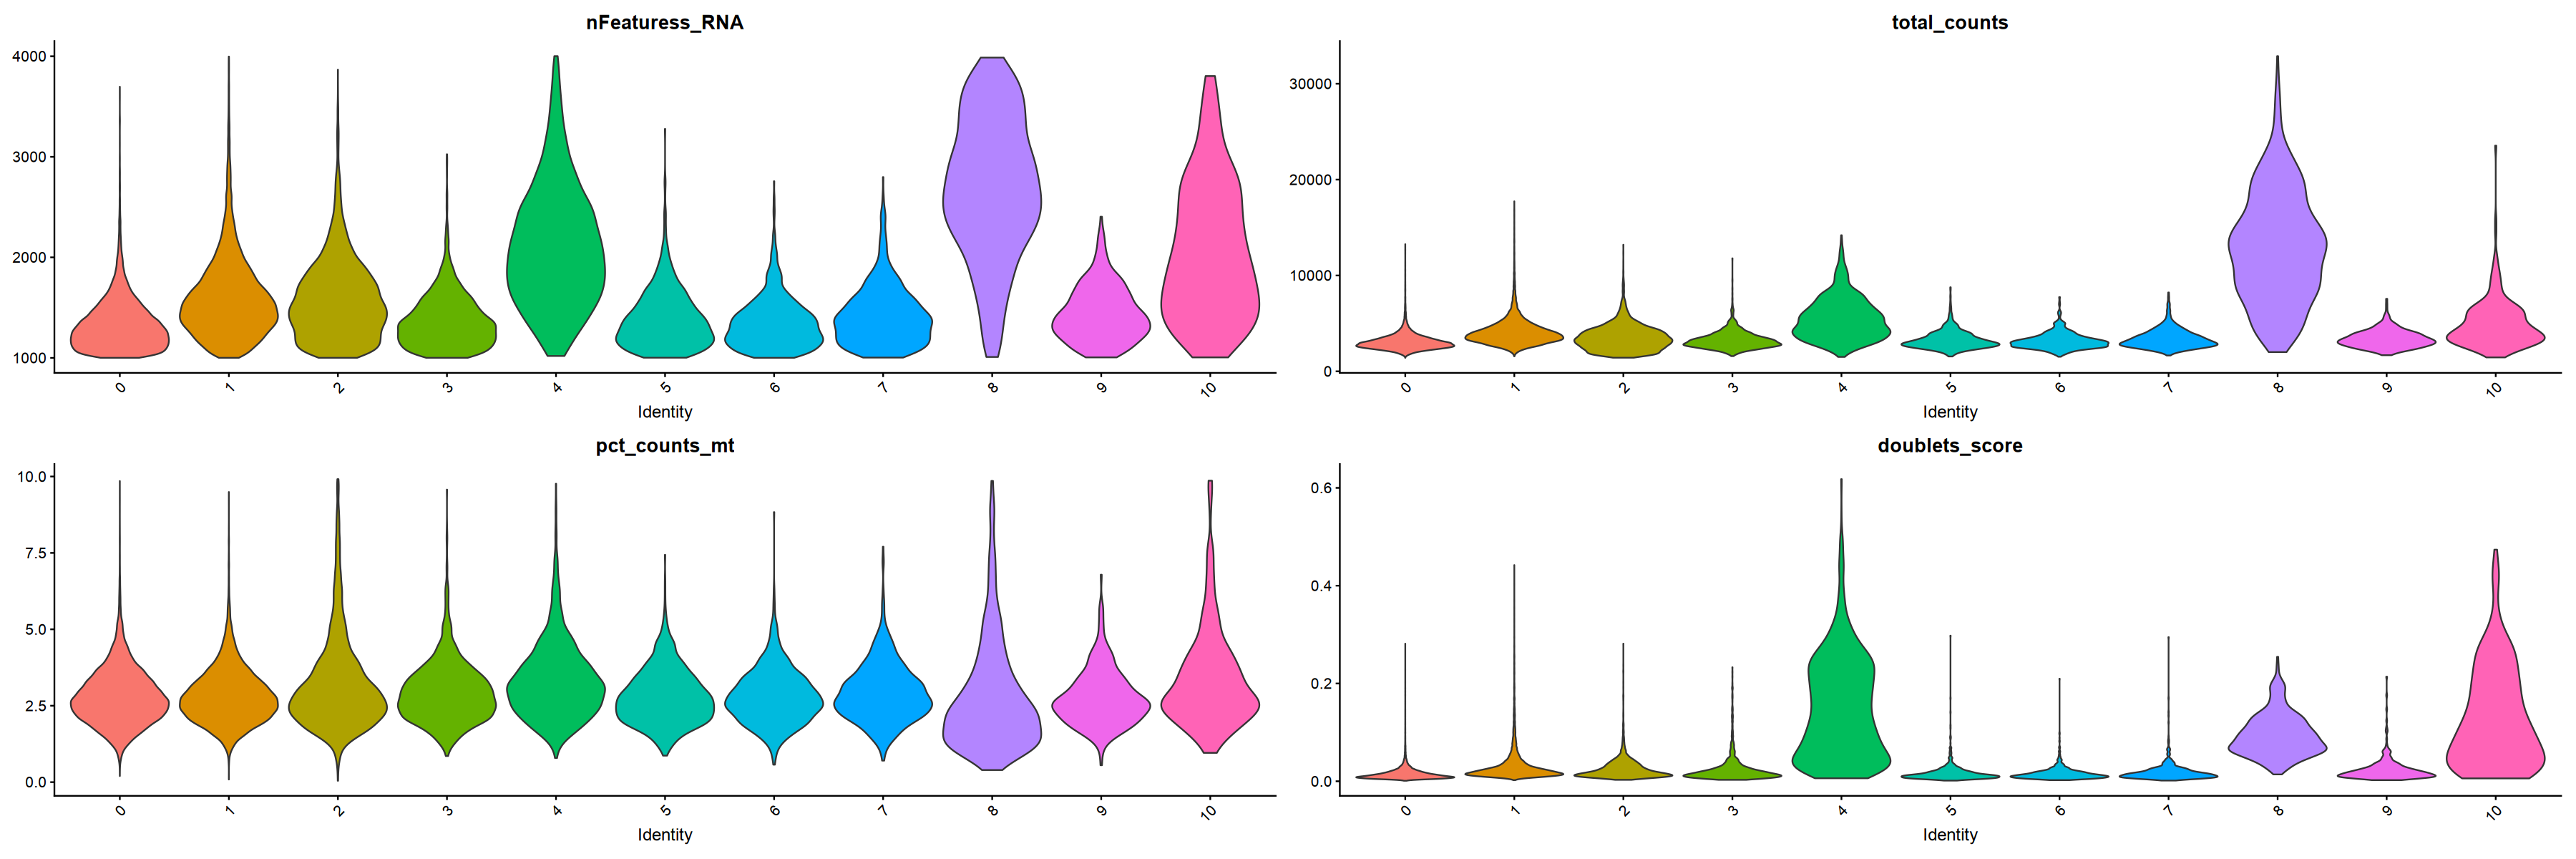

In [13]:
options(repr.plot.width=30, repr.plot.height=10)
# py scrublet calculation
VlnPlot(obj, 
        features = c('nFeaturess_RNA','total_counts','pct_counts_mt','doublets_score'),  
        group.by='seurat_clusters', 
        ncol=2, pt.size=0)

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”


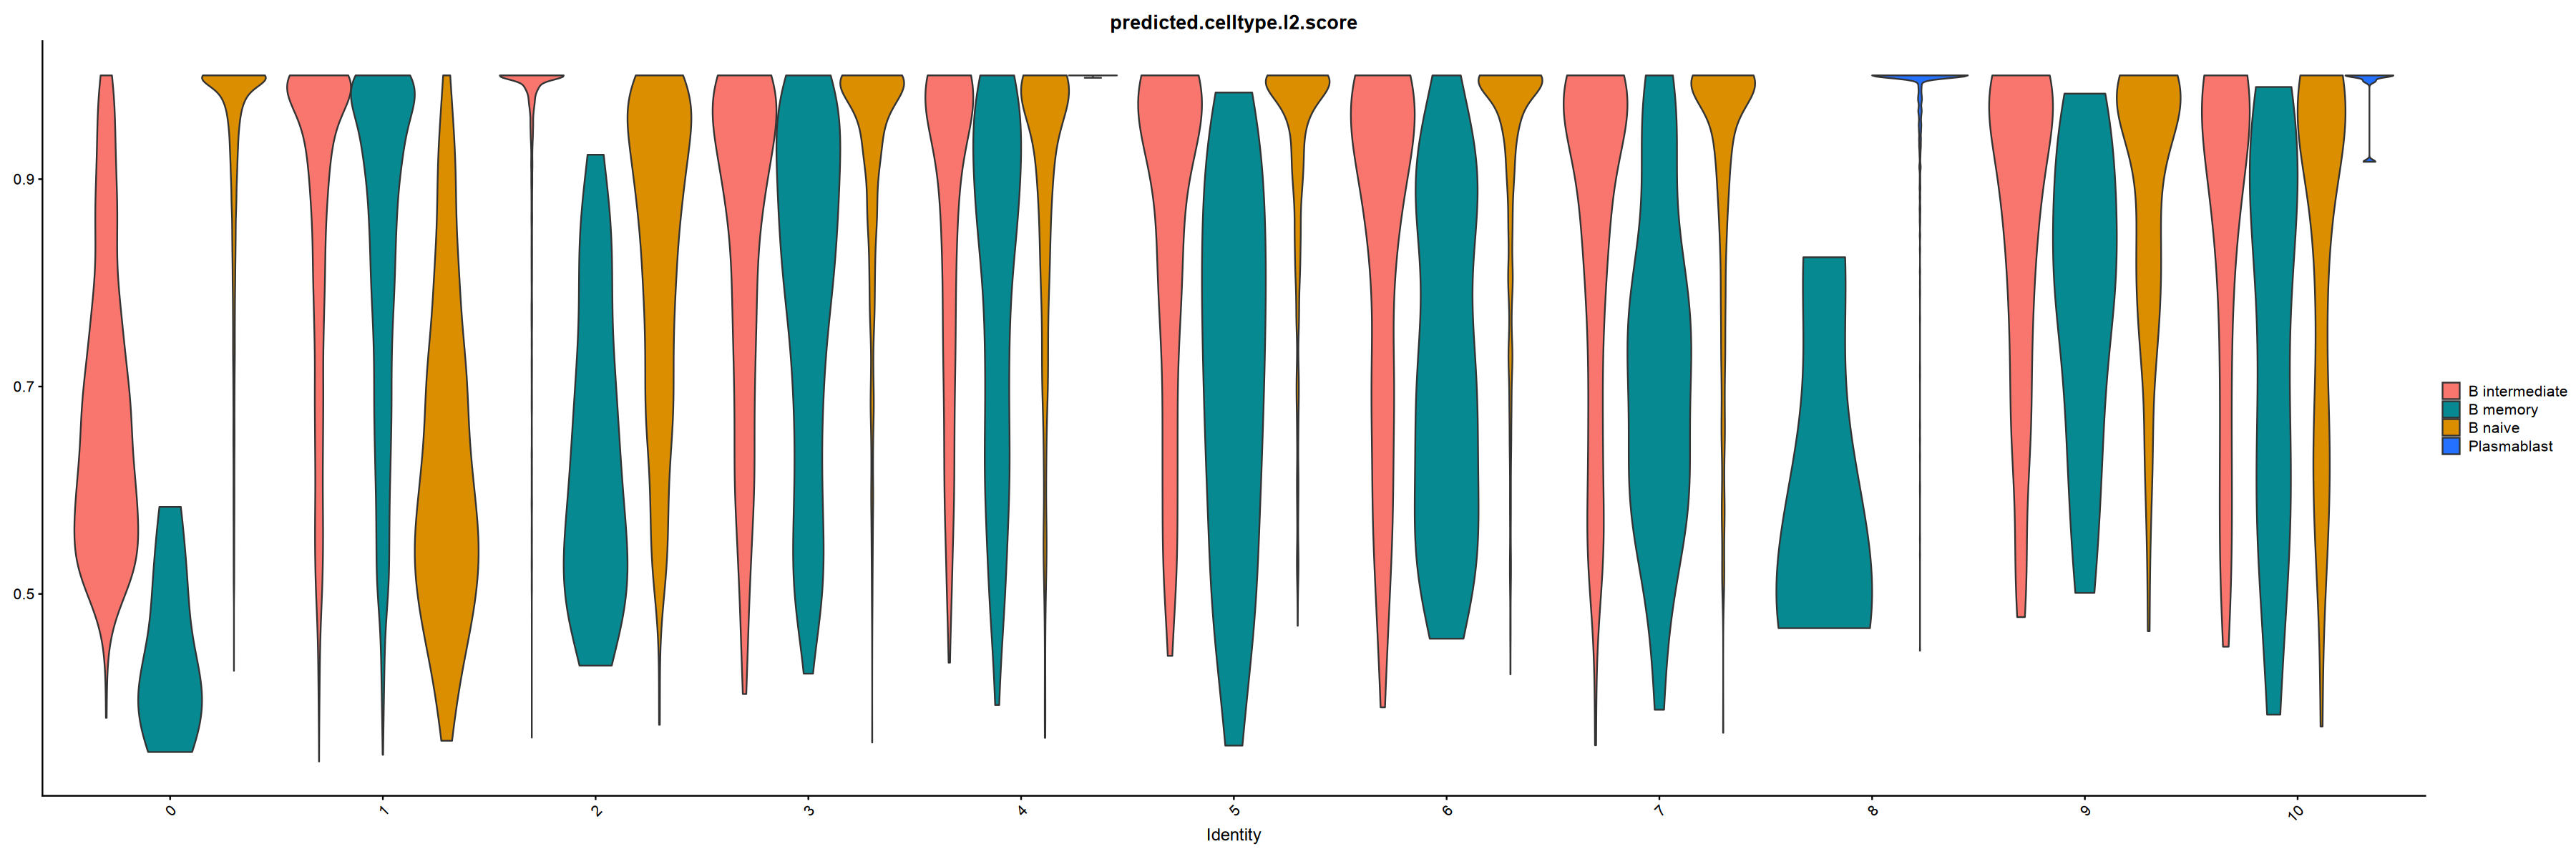

In [23]:
options(repr.plot.width=30, repr.plot.height=10)
# py scrublet calculation
VlnPlot(obj, 
        features = c('predicted.celltype.l2.score'),          
        split.by='predicted.celltype.l2', group.by='seurat_clusters', 
        ncol=1, pt.size=0)

In [27]:
# cluster 4 and 10 are likely doublets
# we filter them and redo clustering

ft = subset(x = obj, 
            subset = !(seurat_clusters %in% c(4,10)))

ft

An object of class Seurat 
28202 features across 51643 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [28]:
ft <- FindNeighbors(ft, dims = 1:30, reduction = "harmony")
ft <- RunUMAP(ft, dims = 1:30, reduction = "harmony")

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 51643
Number of edges: 1476713

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9564
Number of communities: 11
Elapsed time: 13 seconds


1 singletons identified. 10 final clusters.

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
10:57:16 UMAP embedding parameters a = 0.9922 b = 1.112

10:57:16 Read 51643 rows and found 30 numeric columns

10:57:16 Using Annoy for neighbor search, n_neighbors = 30

10:57:16 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

10:57:24 Writing NN index file to temp file /tmp/RtmpuxDsrj/file322f214fb54c1c

10:57:24 Searching Annoy index using 1 thread, search_k = 3000

10:57:49 Annoy recall = 100%

10:57:49 Commencing smooth kNN distance calib

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 51643
Number of edges: 1476713

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9166
Number of communities: 14
Elapsed time: 15 seconds


1 singletons identified. 13 final clusters.



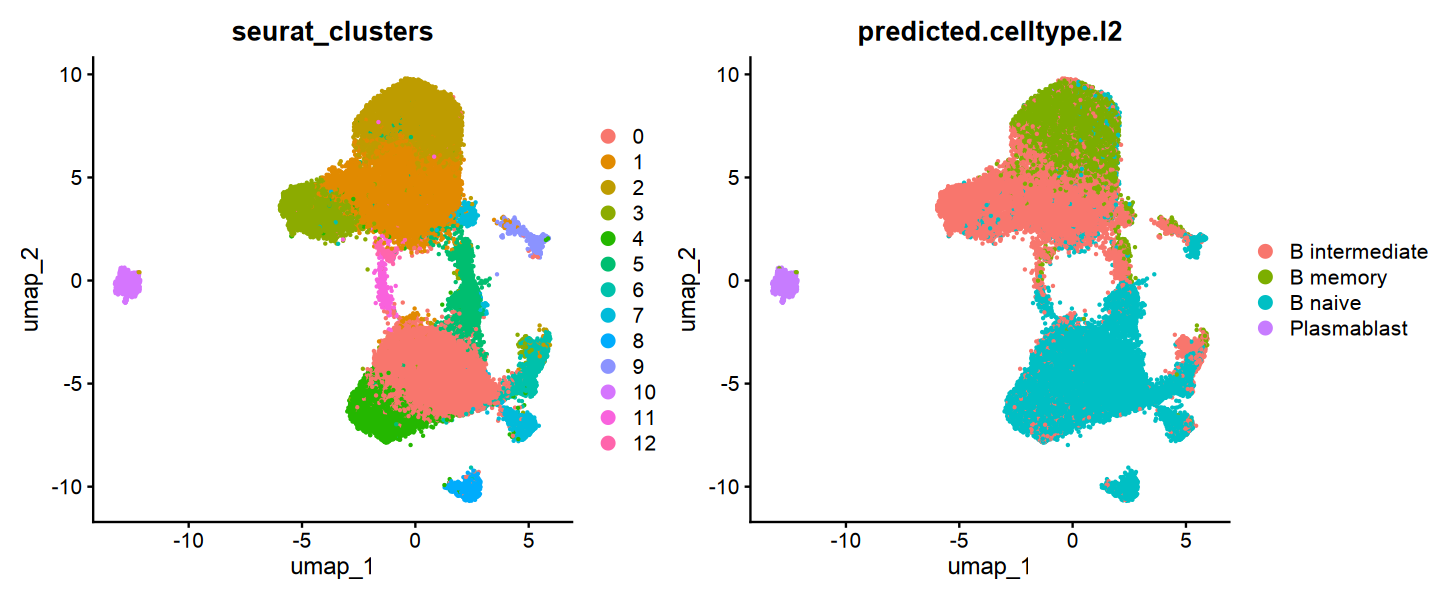

In [45]:
options(repr.plot.width=12, repr.plot.height=5)

ft <- FindClusters(ft, resolution = .3)

DimPlot(ft, reduction = "umap", 
        group.by=c('seurat_clusters','predicted.celltype.l2'),
        ncol=2
       )

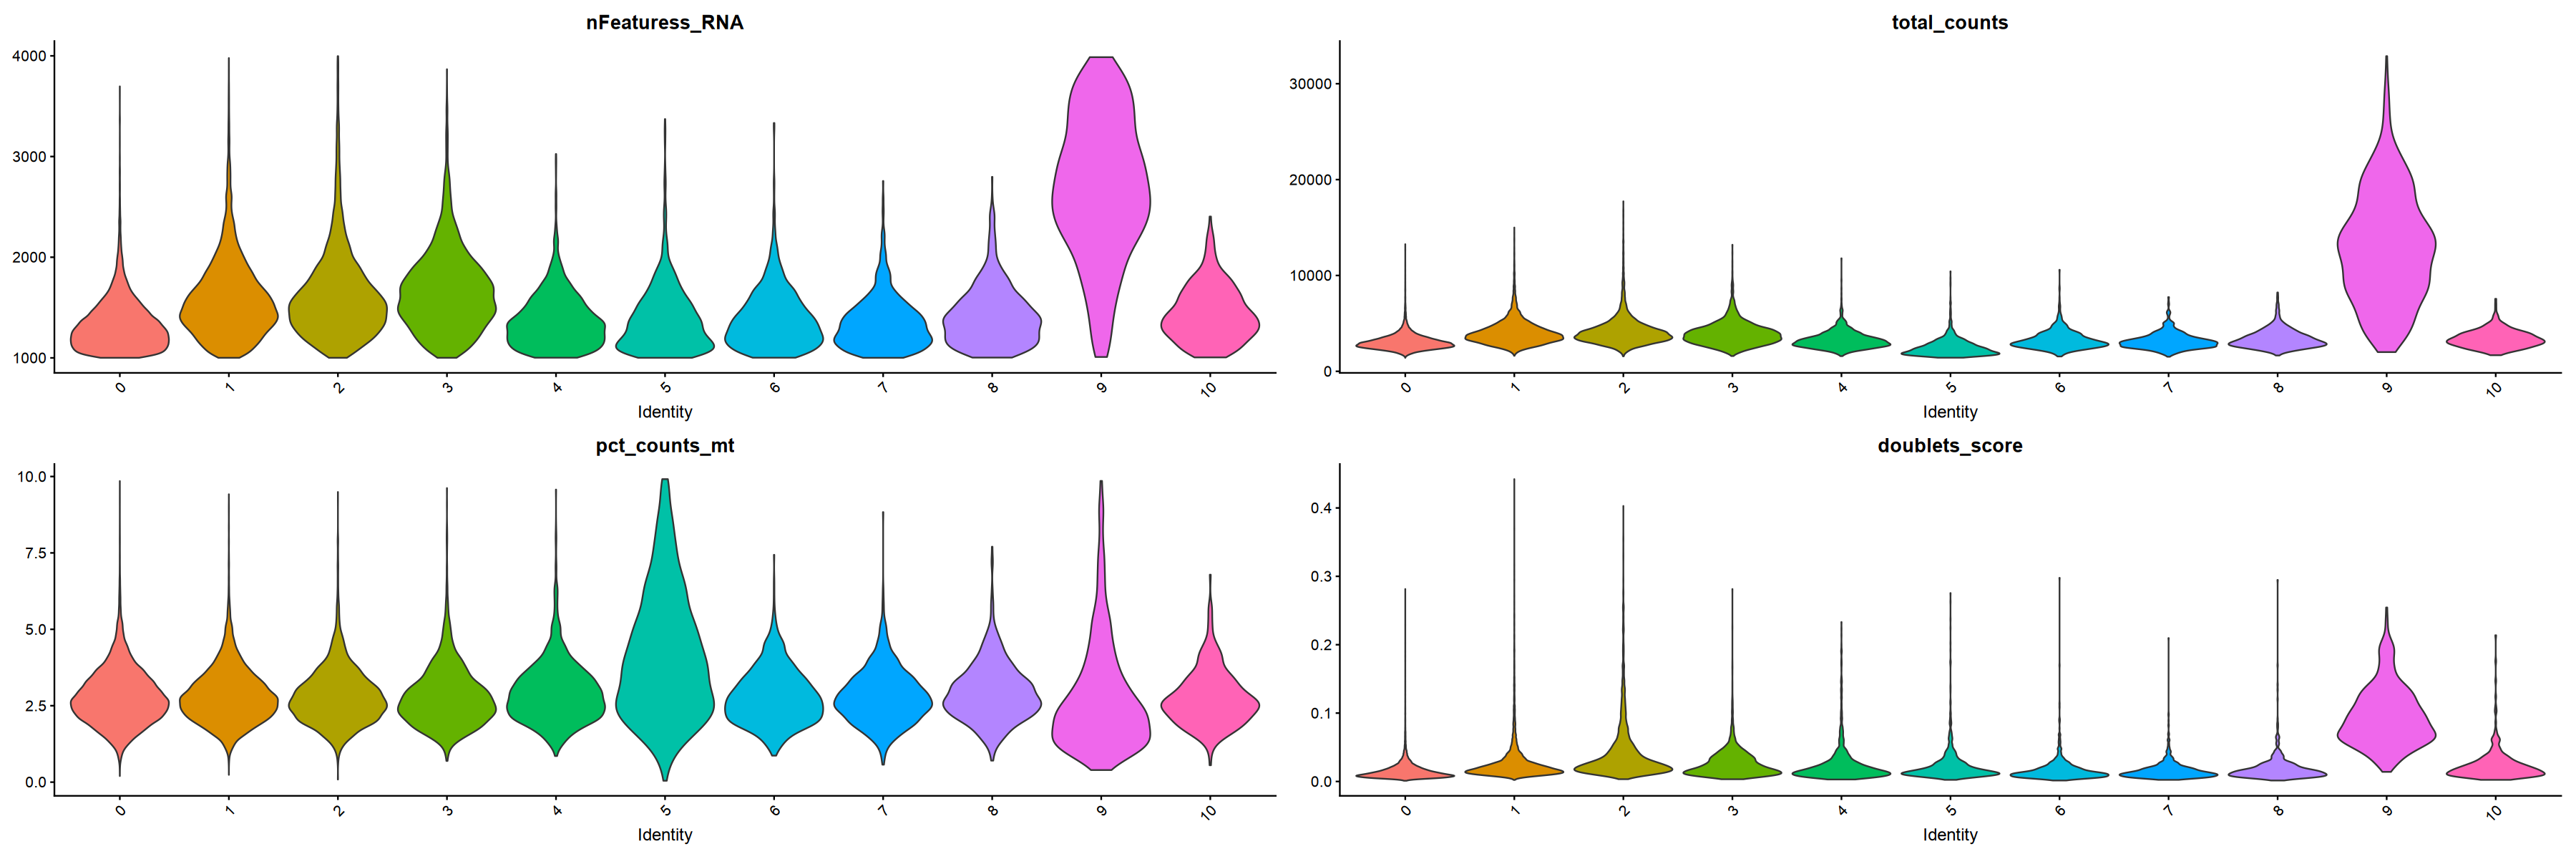

In [34]:
options(repr.plot.width=30, repr.plot.height=10)
# py scrublet calculation
VlnPlot(ft, 
        features = c('nFeaturess_RNA','total_counts','pct_counts_mt','doublets_score'),  
        group.by='seurat_clusters', 
        ncol=2, pt.size=0)

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”


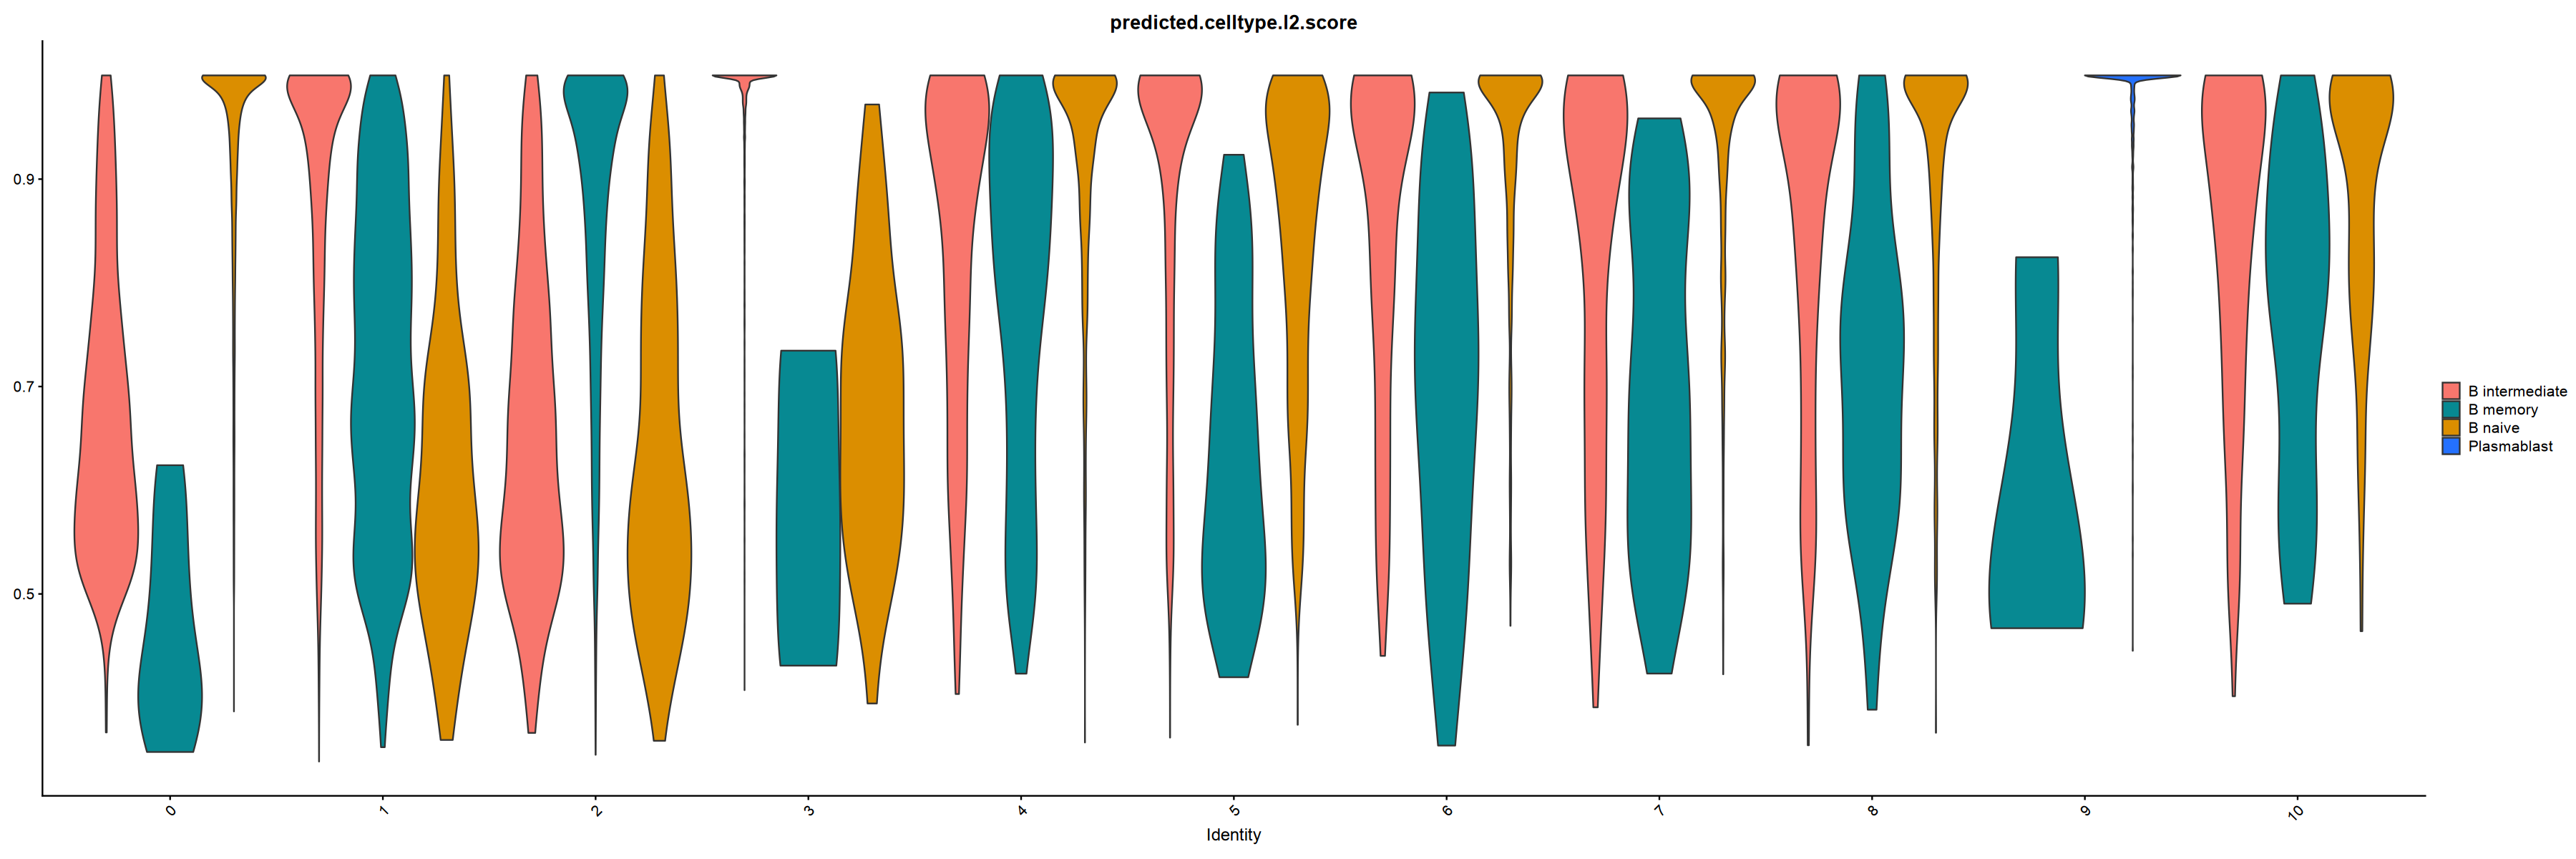

In [35]:
options(repr.plot.width=30, repr.plot.height=10)
# py scrublet calculation
VlnPlot(ft, 
        features = c('predicted.celltype.l2.score'),          
        split.by='predicted.celltype.l2', group.by='seurat_clusters', 
        ncol=1, pt.size=0)

In [119]:
ctab <- table(ft@meta.data[, c('seurat_clusters', 'predicted.celltype.l2')])
ctab_pct <- as.data.frame.matrix(prop.table(ctab, 1) * 100)

ctab_pct

,B intermediate,B memory,B naive,Plasmablast
,<dbl>,<dbl>,<dbl>,<dbl>
0,2.543626,0.04732328,97.409051,0.00000000
1,81.022847,16.74932921,2.227823,0.00000000
2,9.467622,87.21730580,3.301025,0.01404692
3,98.112713,0.07863696,1.808650,0.00000000
4,6.921176,0.02746498,93.051360,0.00000000
5,24.166667,13.77450980,62.058824,0.00000000
6,49.821641,2.49702735,47.681332,0.00000000
7,18.173346,4.19384902,77.632805,0.00000000
8,3.477218,0.11990408,96.402878,0.00000000


In [49]:
max_pct <- apply(ctab_pct, 1, max)
clusters_low_purity <- as.integer(names(max_pct[max_pct < 70]) )
print(clusters_low_purity)

[1]  5  6  9 11


In [120]:
# for those cells which are not in clusters_low_purity, assign top predicted.celltype.l2 for that seurat_clusters
# Assume ft is your Seurat object and clusters_low_purity is already defined

# Step 1: Get cluster to top cell type mapping
ctab <- table(ft@meta.data[, c('seurat_clusters', 'predicted.celltype.l2')])
cluster_majority <- apply(ctab, 1, function(x) names(x)[which.max(x)])

# Step 2: For cells NOT in clusters_low_purity, assign top celltype
valid_clusters <- setdiff(as.integer(rownames(ctab)), clusters_low_purity)

meta_tmp <- ft@meta.data[,'seurat_clusters', drop=F]
meta_tmp$celltype_level3 <- NA  # initialize

mask <- meta_tmp$seurat_clusters %in% valid_clusters
meta_tmp$celltype_level3[mask] <- cluster_majority[as.character(meta_tmp$seurat_clusters[mask])]

anno1 = meta_tmp %>% drop_na()
dim(anno1)                       
head(anno1  )   

[1] 51643     2

,seurat_clusters,celltype_level3
,<fct>,<chr>
Pool137_10_AAACCTGAGGTGATTA-1,0,B naive
Pool137_10_AAACGGGGTGCAACGA-1,0,B naive
Pool137_10_AACACGTGTGTTCTTT-1,4,B naive
Pool137_10_AACACGTTCACCTTAT-1,4,B naive
Pool137_10_AACGTTGAGAGCCCAA-1,0,B naive
Pool137_10_AACTTTCCAAAGCAAT-1,0,B naive


In [88]:
# for clusters have ambiguous assignment ratio (top assignment % <= 70%) - we will subset them and recluster

sub = subset(x = ft, 
            subset = seurat_clusters %in% clusters_low_purity)

sub <- FindNeighbors(sub, dims = 1:30, reduction = "harmony")
sub <- RunUMAP(sub, dims = 1:30, reduction = "harmony")

Computing nearest neighbor graph

Computing SNN

11:26:30 UMAP embedding parameters a = 0.9922 b = 1.112

11:26:30 Read 4893 rows and found 30 numeric columns

11:26:30 Using Annoy for neighbor search, n_neighbors = 30

11:26:30 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

11:26:31 Writing NN index file to temp file /tmp/RtmpuxDsrj/file322f21438dfb0e

11:26:31 Searching Annoy index using 1 thread, search_k = 3000

11:26:33 Annoy recall = 100%

11:26:33 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

11:26:34 Initializing from normalized Laplacian + noise (using RSpectra)

11:26:34 Commencing optimization for 500 epochs, with 231632 positive edges

11:26:34 Using rng type: pcg

11:26:41 Optimization finished



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 4893
Number of edges: 224594

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8510
Number of communities: 9
Elapsed time: 0 seconds


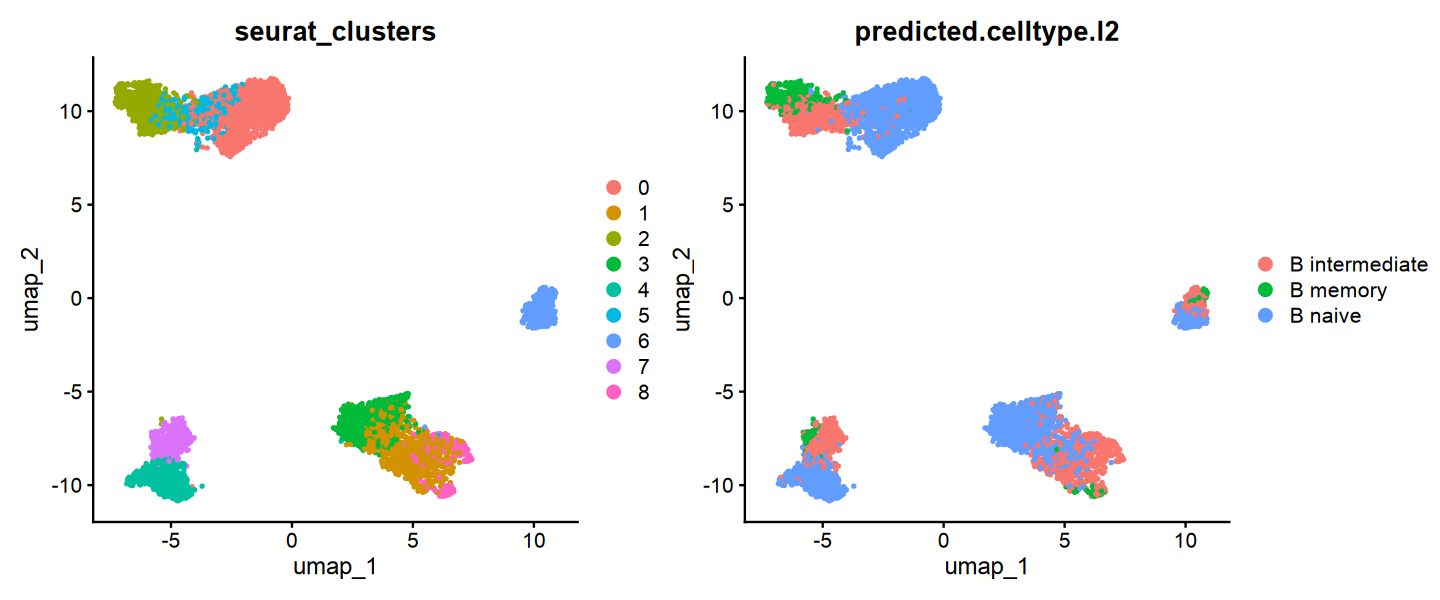

In [98]:
sub <- FindClusters(sub, resolution = .7)

DimPlot(sub, reduction = "umap", 
        group.by=c('seurat_clusters','predicted.celltype.l2'),
        ncol=2
       )

In [99]:
ctab <- table(sub@meta.data[, c('seurat_clusters', 'predicted.celltype.l2')])
ctab_pct <- as.data.frame.matrix(prop.table(ctab, 1) * 100)

ctab_pct

,B intermediate,B memory,B naive
,<dbl>,<dbl>,<dbl>
0,4.757548,0.6404392,94.602013
1,62.731481,1.9675926,35.300926
2,55.172414,42.4137931,2.413793
3,15.156794,0.1742160,84.668990
4,7.984032,0.3992016,91.616766
5,32.620321,7.7540107,59.625668
6,38.904899,8.3573487,52.737752
7,76.947040,17.1339564,5.919003
8,87.029289,10.0418410,2.928870


In [100]:
max_pct <- apply(ctab_pct, 1, max)
clusters_low_purity <- as.integer(names(max_pct[max_pct < 50]) )
print(clusters_low_purity)

integer(0)


In [113]:
# for those cells which are not in clusters_low_purity, assign top predicted.celltype.l2 for that seurat_clusters
# Assume ft is your Seurat object and clusters_low_purity is already defined

# Step 1: Get cluster to top cell type mapping
ctab <- table(sub@meta.data[, c('seurat_clusters', 'predicted.celltype.l2')])
cluster_majority <- apply(ctab, 1, function(x) names(x)[which.max(x)])

# Step 2: For cells NOT in clusters_low_purity, assign top celltype
valid_clusters <- as.integer(rownames(ctab))

meta_tmp <- sub@meta.data[,'seurat_clusters', drop=F]
meta_tmp$celltype_level3 <- NA  # initialize

mask <- meta_tmp$seurat_clusters %in% valid_clusters
meta_tmp$celltype_level3[mask] <- cluster_majority[as.character(meta_tmp$seurat_clusters[mask])]

anno2 = meta_tmp %>% drop_na()
dim(anno2)                       
head(anno2)   

[1] 4893    2

,seurat_clusters,celltype_level3
,<fct>,<chr>
Pool137_10_ACTGTCCTCACATAGC-1,0,B naive
Pool137_10_AGATCTGCACCACGTG-1,0,B naive
Pool137_10_AGCAGCCAGGCGACAT-1,5,B naive
Pool137_10_AGGCCACCACGTCTCT-1,0,B naive
Pool137_10_AGGTCATTCGTCCGTT-1,7,B intermediate
Pool137_10_ATGCGATAGAAAGTGG-1,7,B intermediate


In [102]:
dim(anno1)[1] + dim(anno2)[1]
dim(ft)

[1] 51643

[1] 27879 51643

In [124]:
anno = rbind(anno1, anno2)

anno = anno[Cells(ft),]

dim(anno)
head(anno)

[1] 51643     2

,seurat_clusters,celltype_level3
,<fct>,<chr>
Pool137_10_AAACCTGAGGTGATTA-1,0,B naive
Pool137_10_AAACGGGGTGCAACGA-1,0,B naive
Pool137_10_AACACGTGTGTTCTTT-1,4,B naive
Pool137_10_AACACGTTCACCTTAT-1,4,B naive
Pool137_10_AACGTTGAGAGCCCAA-1,0,B naive
Pool137_10_AACTTTCCAAAGCAAT-1,0,B naive


In [125]:
ft = AddMetaData(ft, 
                 metadata = anno$celltype_level3, 
                 col.name = "celltype_level3")

## Save

In [6]:
map <- c(
  "B naive" = "Naive B",
  "B intermediate" = "Mature B",
  "B memory" = "Memory B",
  "Plasmablast" = "Plasmablast"
)

# Map values
ft@meta.data[['celltype_level3']] <- map[ ft@meta.data[['celltype_level3']] ]

In [46]:
cell_ordered = c(
  "Naive B",
  "Mature B",
  "Memory B",
  "Plasmablast"

)

ft@meta.data[['celltype_level3']] = factor(
    ft@meta.data[['celltype_level3']],
    levels = cell_ordered
)

In [48]:
qs::qsave(ft, glue('data/03_cleandata/ft_{celltype}.qs'))

# Visualize

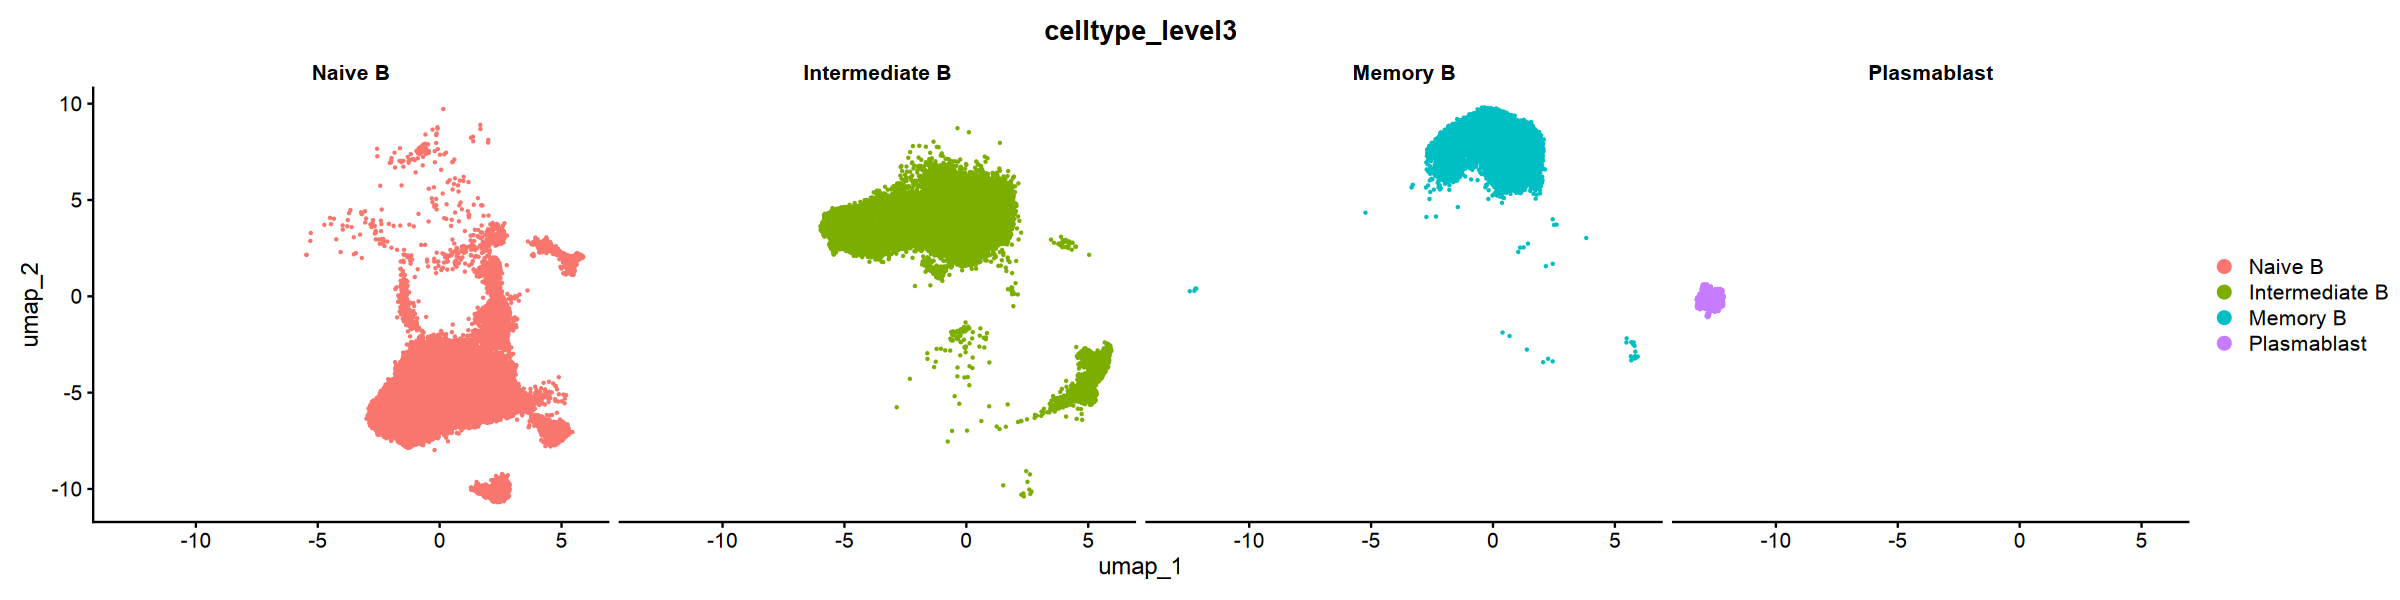

In [14]:
options(repr.plot.width=20, repr.plot.height=5)

varname = 'celltype_level3'
DimPlot(ft, reduction = "umap",  
        group.by = varname,
        split.by = varname)

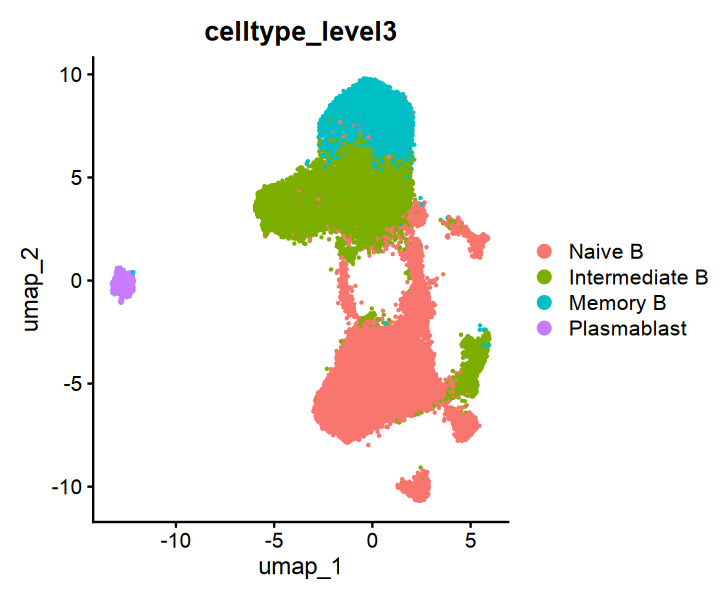

In [15]:
options(repr.plot.width=6, repr.plot.height=5)

DimPlot(ft, reduction = "umap", group.by='celltype_level3')

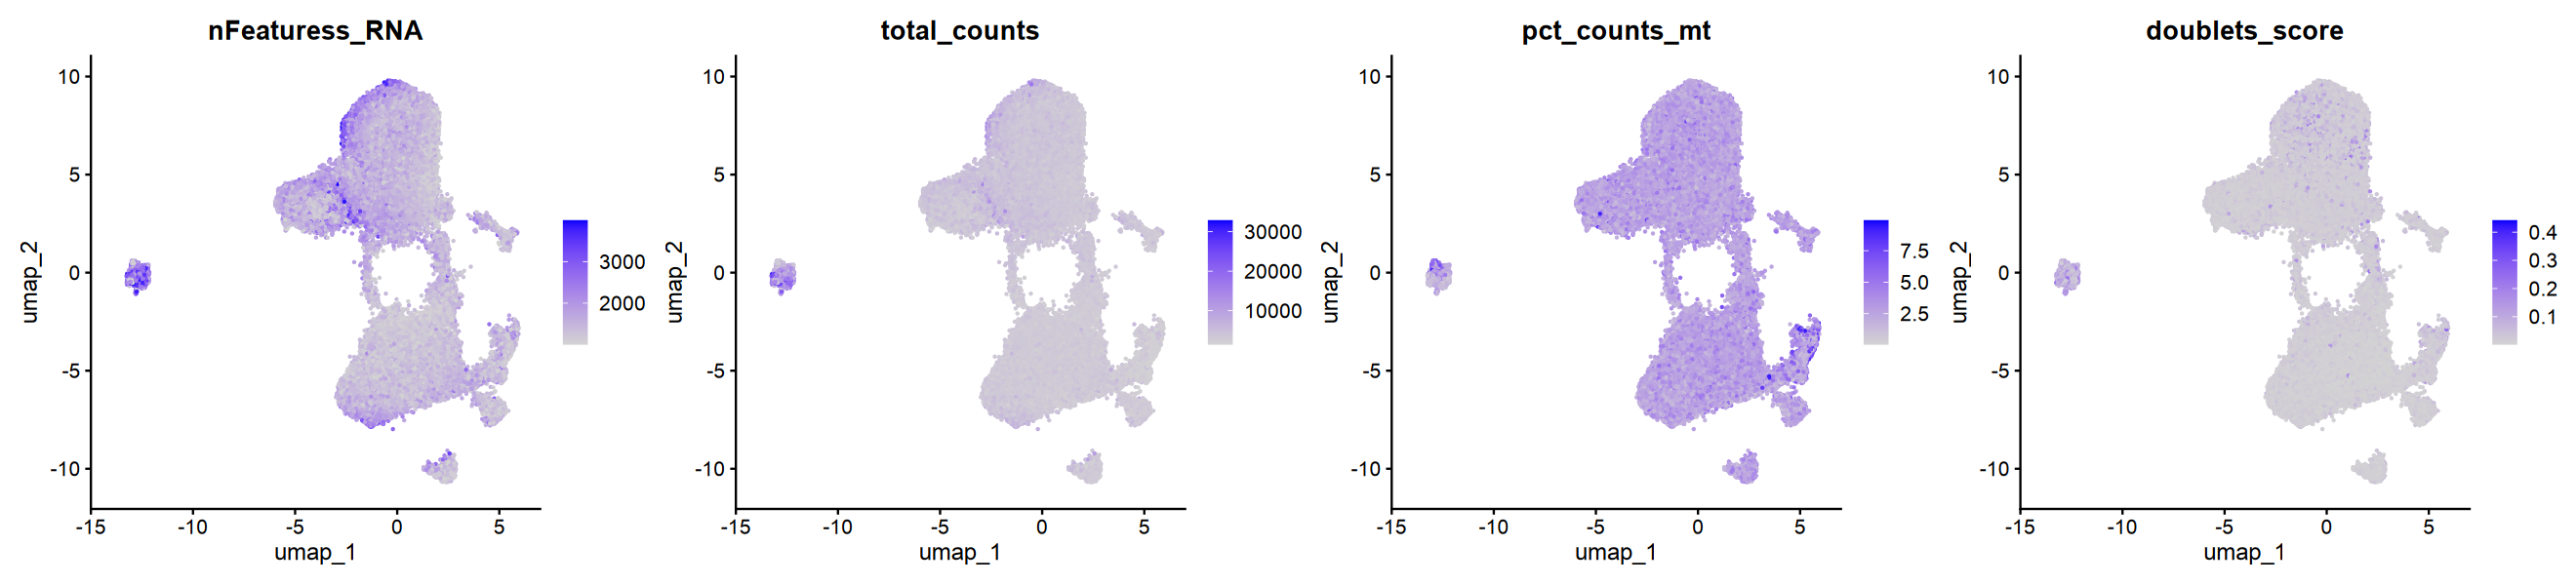

In [16]:
options(repr.plot.width=22, repr.plot.height=5)

FeaturePlot(ft, 
            features = c('nFeaturess_RNA','total_counts','pct_counts_mt','doublets_score'),  
            reduction = 'umap', ncol=4)

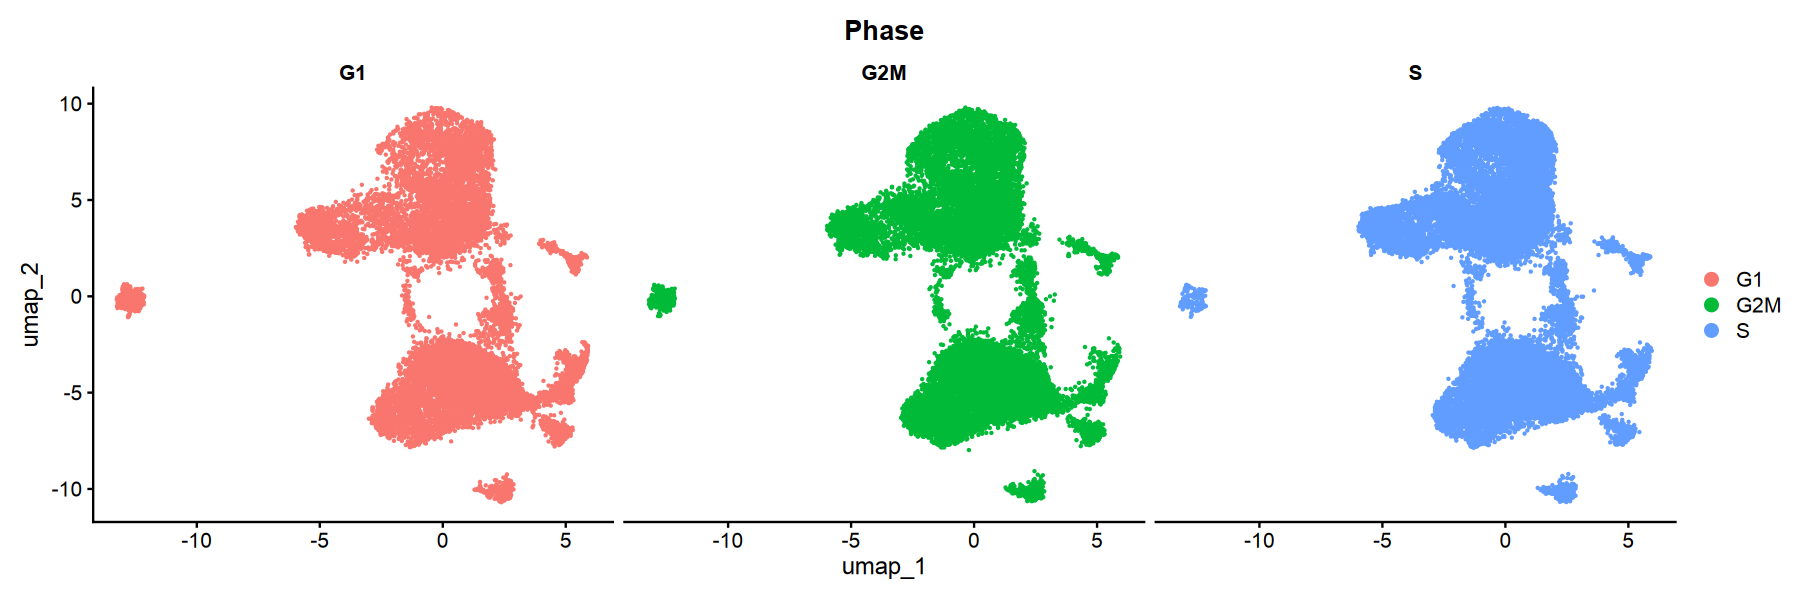

In [17]:
options(repr.plot.width=15, repr.plot.height=5)
varname = 'Phase'
DimPlot(ft, reduction = "umap",  
        group.by = varname,
        split.by = varname)

In [18]:
length(unique(ft@meta.data$dataset_name))

[1] 56

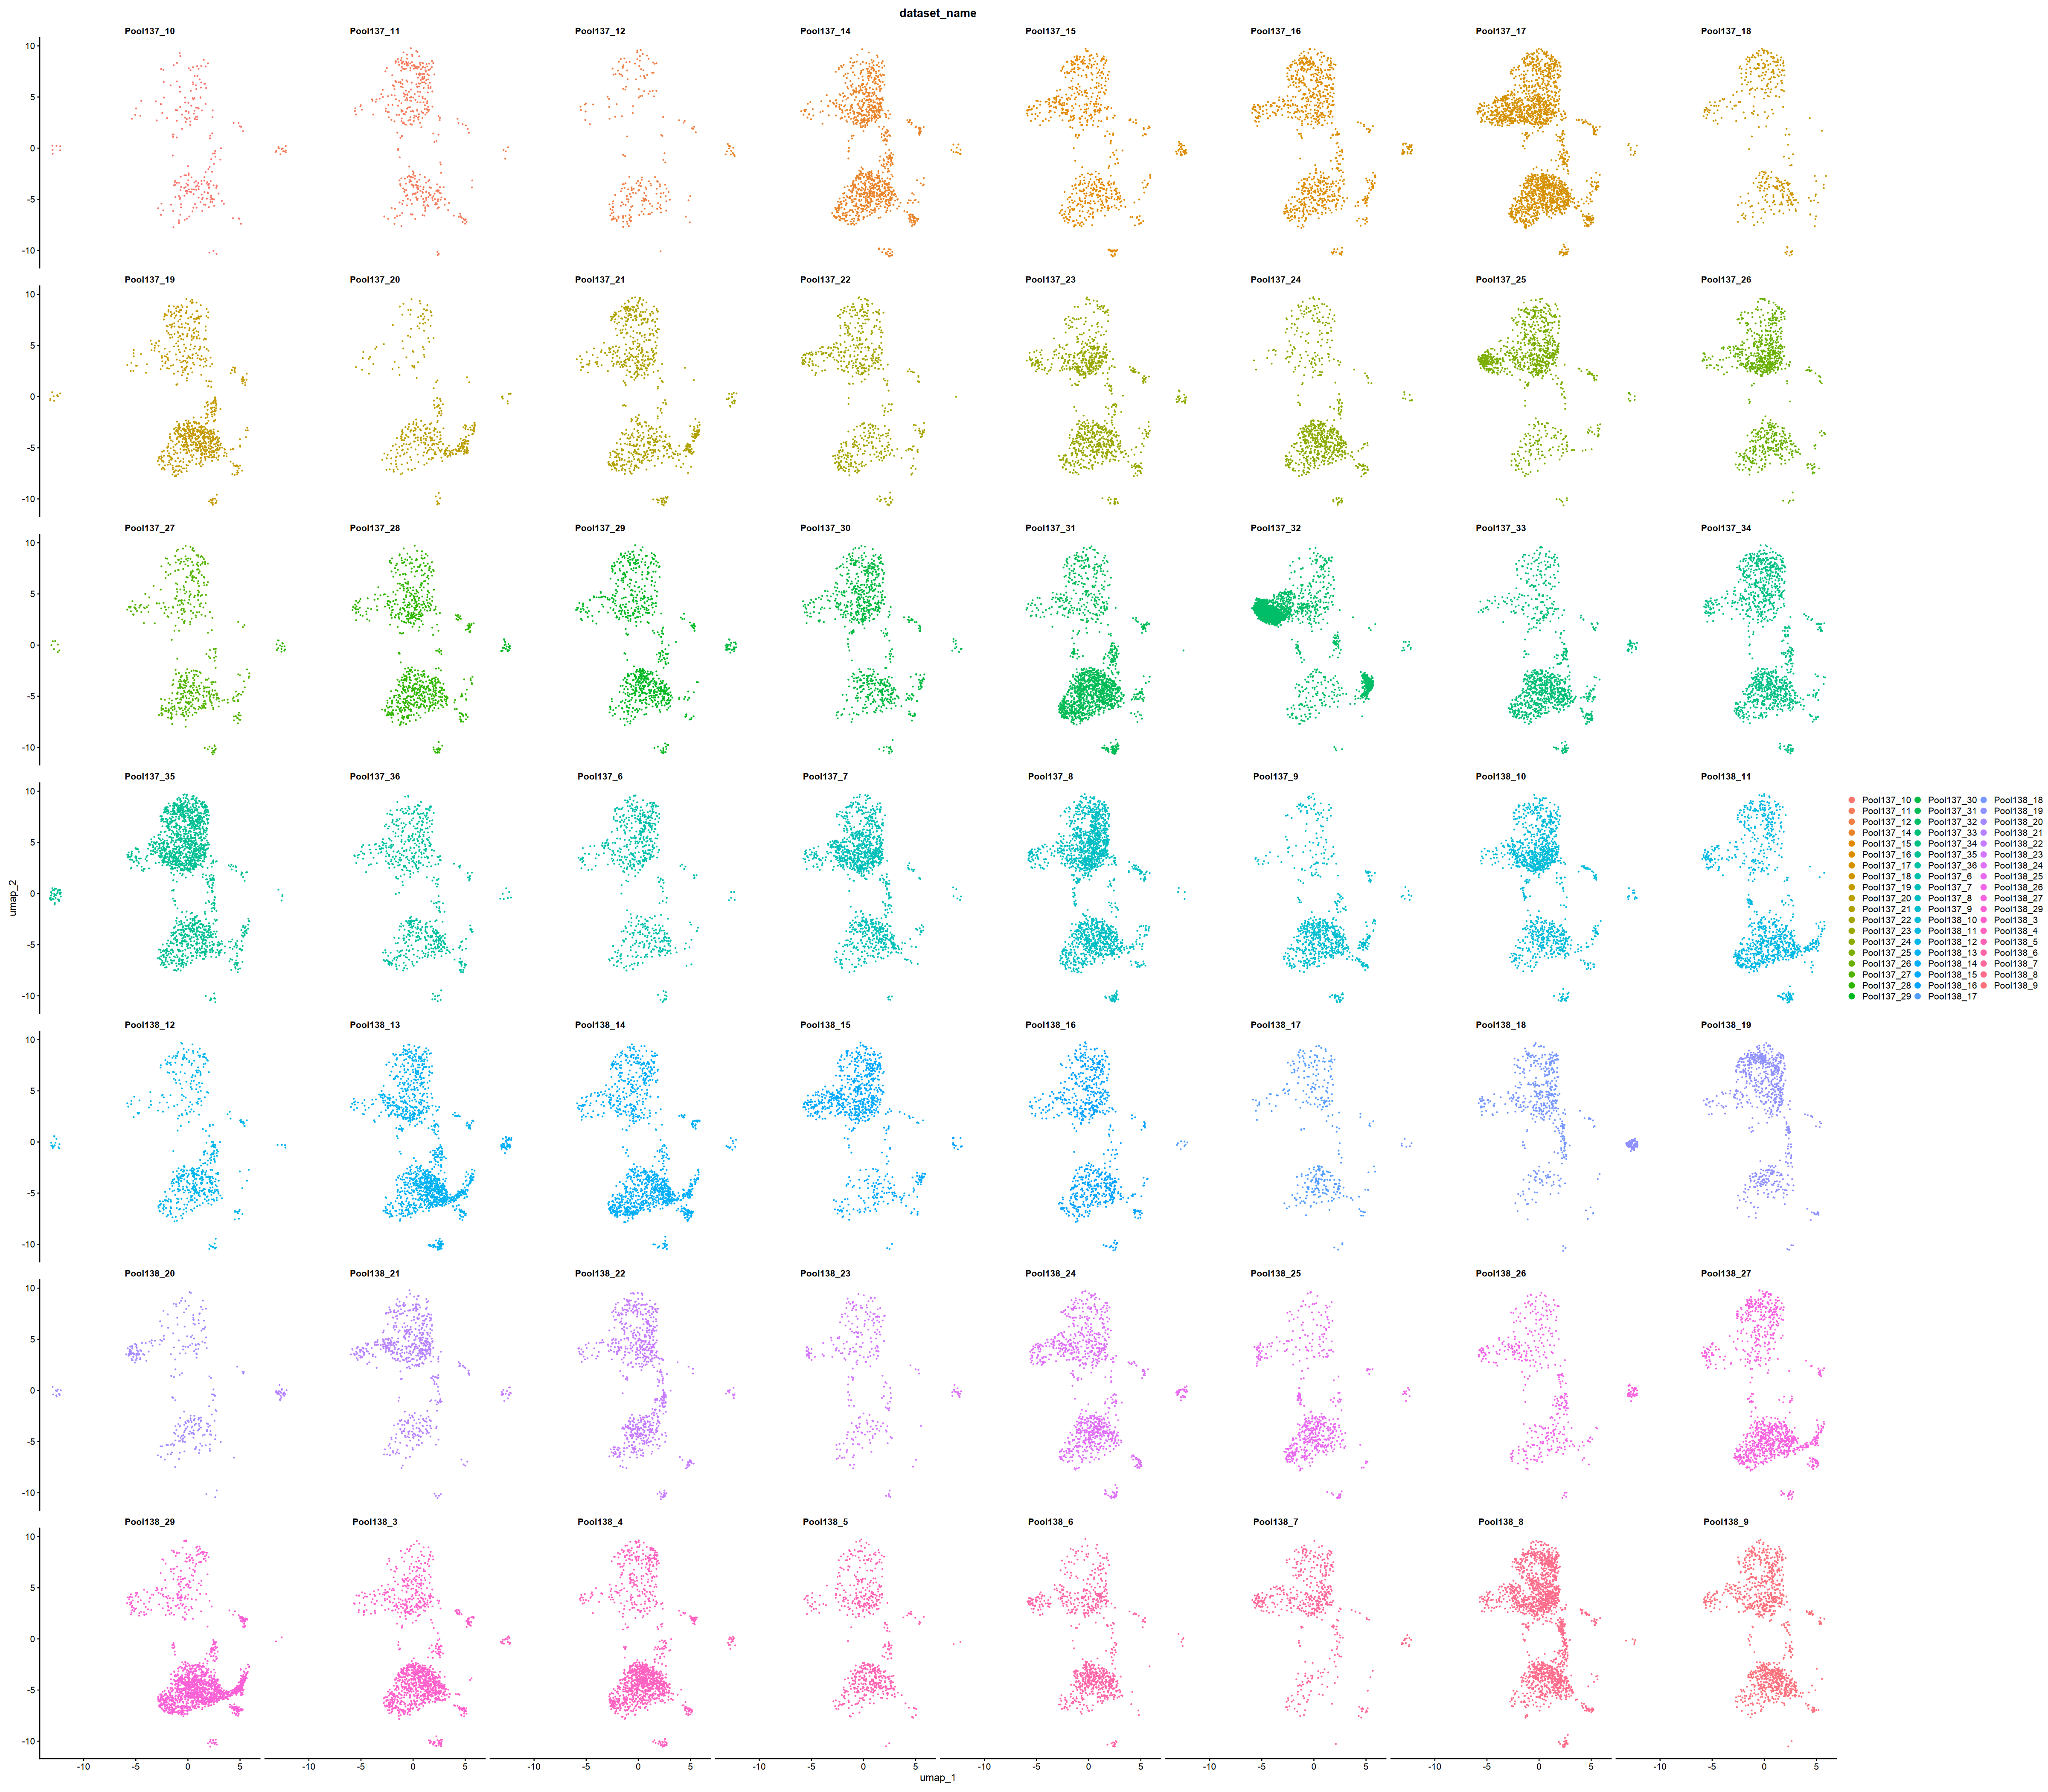

In [19]:
options(repr.plot.width=40, repr.plot.height=35)

varname = 'dataset_name'
DimPlot(ft, reduction = "umap",  
        ncol = 8,
        group.by = varname,
        split.by = varname)

# DEGs

In [49]:
Idents(ft) <- "celltype_level3"
markers <- FindAllMarkers(ft, verbose = T)
head(markers)

Calculating cluster Naive B

Calculating cluster Mature B

Calculating cluster Memory B

Calculating cluster Plasmablast



,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
TCL1A,0,3.106836,0.833,0.116,0,Naive B,TCL1A
CRIP1,0,-2.680403,0.278,0.742,0,Naive B,CRIP1
IL4R,0,2.910159,0.559,0.101,0,Naive B,IL4R
FCER2,0,2.150734,0.712,0.275,0,Naive B,FCER2
IGHA1,0,-5.019416,0.032,0.449,0,Naive B,IGHA1
TNFRSF13B,0,-3.124227,0.055,0.453,0,Naive B,TNFRSF13B


In [50]:
write.csv(markers, 
          glue('data/04_markergenes/{celltype}.csv'))

In [51]:
markers = read.csv(glue('data/04_markergenes/{celltype}.csv'),
                   row.names=1
                  )

cell_ordered = c(
    "Naive B",
    "Mature B",
    "Memory B",
    "Plasmablast"
)

markers$cluster = factor(
    markers$cluster,
    levels = cell_ordered
)


In [52]:
markers %>%
    group_by(cluster) %>%
    filter(p_val_adj < 0.05) %>%
    dplyr::filter(avg_log2FC > 1) %>%
    slice_head(n = 10) %>%
    ungroup() -> top10

top10

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
0,3.106836,0.833,0.116,0,Naive B,TCL1A
0,2.910159,0.559,0.101,0,Naive B,IL4R
0,2.150734,0.712,0.275,0,Naive B,FCER2
0,1.749376,0.619,0.238,0,Naive B,IGHD
0,2.228129,0.591,0.226,0,Naive B,PLPP5
0,1.572586,0.624,0.291,0,Naive B,COL19A1
0,1.001176,0.927,0.637,0,Naive B,BACH2
0,1.585856,0.427,0.153,0,Naive B,YBX3
0,2.001756,0.416,0.143,0,Naive B,APLP2


Warning message:
“Scaling data with a low number of groups may produce misleading results”
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


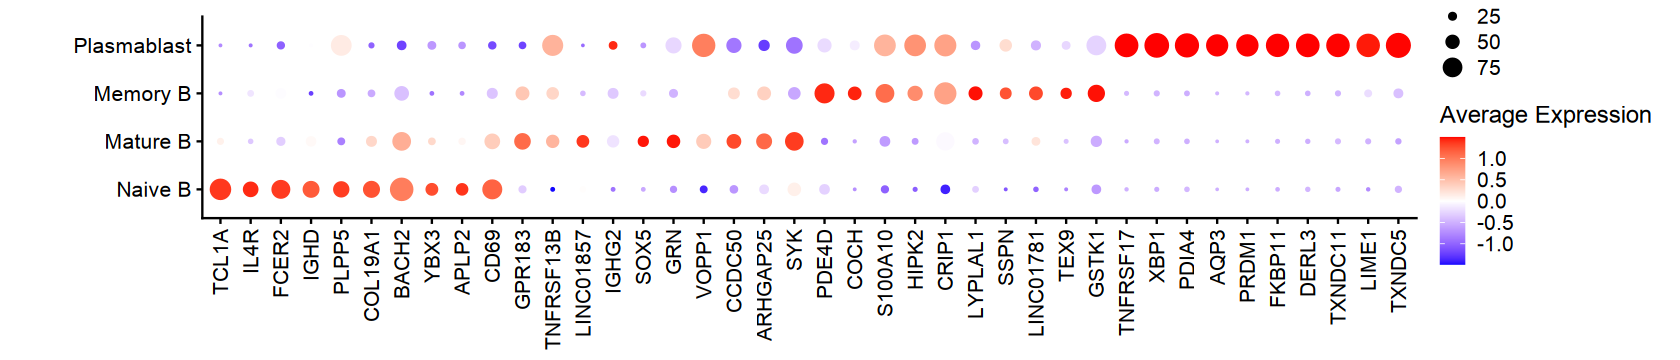

In [53]:
options(repr.plot.width=14, repr.plot.height=3)

p <- DotPlot(
  object = ft,
  features = unique(unlist(top10$gene)),
  group.by = "celltype_level3"
) +
  scale_color_gradient2(
    low = "blue",
    mid = "white",
    high = "red",
    midpoint = 0
  ) +
  theme(
    axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1),
    axis.title.x = element_blank(),
    axis.title.y = element_blank(),
    plot.margin = margin(t = 10, r = 20, b = 10, l = 50)
  )


print(p)

In [54]:
marker_azi = read.csv('data/04_markergenes/azimuth_markers.csv')
marker_azi

Level,Label,Expanded.Label,OBO.Ontology.ID,Markers
<int>,<chr>,<chr>,<chr>,<chr>
1,Mono,Monocyte,monocyte,"CTSS, FCN1, NEAT1, LYZ, PSAP, S100A9, AIF1, MNDA, SERPINA1, TYROBP"
1,CD4 T,CD4+ T cell,"CD4-positive, alpha-beta T cell","IL7R, MAL, LTB, CD4, LDHB, TPT1, TRAC, TMSB10, CD3D, CD3G"
1,CD8 T,CD8+ T cell,"CD8-positive, alpha-beta T cell","CD8B, CD8A, CD3D, TMSB10, HCST, CD3G, LINC02446, CTSW, CD3E, TRAC"
1,NK,natural killer cell,natural killer cell,"NKG7, KLRD1, TYROBP, GNLY, FCER1G, PRF1, CD247, KLRF1, CST7, GZMB"
1,B,B cell,mature B cell,"CD79A, RALGPS2, CD79B, MS4A1, BANK1, CD74, TNFRSF13C, HLA-DQA1, IGHM, MEF2C"
1,other T,other T cell,mature T cell,"CD3D, TRDC, GZMK, KLRB1, NKG7, TRGC2, CST7, LYAR, KLRG1, GZMA"
1,DC,dendritic cell,dendritic cell,"CD74, HLA-DPA1, HLA-DPB1, HLA-DQA1, CCDC88A, HLA-DRA, HLA-DMA, CST3, HLA-DQB1, HLA-DRB1"
2,B intermediate,Intermediate B cell,mature B cell,"MS4A1, TNFRSF13B, IGHM, IGHD, AIM2, CD79A, LINC01857, RALGPS2, BANK1, CD79B"
2,B memory,Memory B cell,memory B cell,"MS4A1, COCH, AIM2, BANK1, SSPN, CD79A, TEX9, RALGPS2, TNFRSF13C, LINC01781"


In [55]:
names_sel <- c(
  "B naive",
  "B memory",
  "B intermediate",
  "Plasmablast"
    )  # <- your cell types of interest

# Filter marker_azi for the selected labels
marker_df <- marker_azi %>% 
filter(Level == 2) %>%
filter(Label %in% names_sel)

# Split the comma-separated Markers into list elements, assign names
markers <- setNames(
  strsplit(marker_df$Markers, ",\\s*"),   # split each marker by comma + space
  marker_df$Label
)

markers

$`B intermediate`
 [1] "MS4A1"     "TNFRSF13B" "IGHM"      "IGHD"      "AIM2"      "CD79A"    
 [7] "LINC01857" "RALGPS2"   "BANK1"     "CD79B"    

$`B memory`
 [1] "MS4A1"     "COCH"      "AIM2"      "BANK1"     "SSPN"      "CD79A"    
 [7] "TEX9"      "RALGPS2"   "TNFRSF13C" "LINC01781"

$`B naive`
 [1] "IGHM"  "IGHD"  "CD79A" "IL4R"  "MS4A1" "CXCR4" "BTG1"  "TCL1A" "CD79B"
[10] "YBX3" 

$Plasmablast
 [1] "IGHA2"     "MZB1"      "TNFRSF17"  "DERL3"     "TXNDC5"    "TNFRSF13B"
 [7] "POU2AF1"   "CPNE5"     "HRASLS2"   "NT5DC2"

In [56]:
# Set your desired cell type order:
type_order <- c("B naive", "B intermediate", "B memory", "Plasmablast")

# Unlist markers in that order, dropping duplicates but preserving order:
features_to_plot <- unlist(markers[type_order], use.names = FALSE)
features_to_plot <- features_to_plot[!duplicated(features_to_plot)]  # Remove duplicates, keep order

# Optionally, keep only genes present in your Seurat object:
features_to_plot <- features_to_plot[features_to_plot %in% rownames(ft)]
features_to_plot

[1] "IGHM"      "IGHD"      "CD79A"     "IL4R"      "MS4A1"     "CXCR4"    
 [7] "BTG1"      "TCL1A"     "CD79B"     "YBX3"      "TNFRSF13B" "AIM2"     
[13] "LINC01857" "RALGPS2"   "BANK1"     "COCH"      "SSPN"      "TEX9"     
[19] "TNFRSF13C" "LINC01781" "IGHA2"     "MZB1"      "TNFRSF17"  "DERL3"    
[25] "TXNDC5"    "POU2AF1"   "CPNE5"     "NT5DC2"

Warning message:
“Scaling data with a low number of groups may produce misleading results”
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


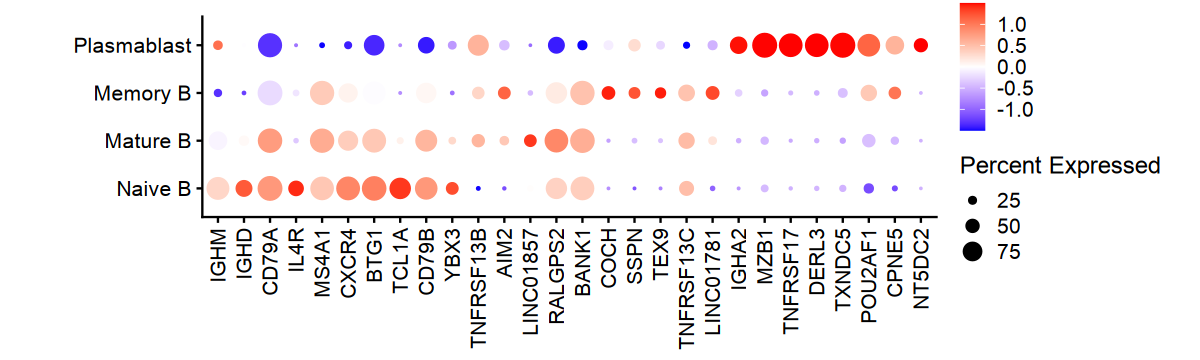

In [57]:
options(repr.plot.width=10, repr.plot.height=3)

p <- DotPlot(
  object = ft,
  features = features_to_plot,
  group.by = "celltype_level3"
) +
  scale_color_gradient2(
    low = "blue",
    mid = "white",
    high = "red",
    midpoint = 0
  ) +
  theme(
    axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1),
    axis.title.x = element_blank(),
    axis.title.y = element_blank(),
    plot.margin = margin(t = 10, r = 20, b = 10, l = 50)
  )

print(p)

# MS4A1''TNFRSF13B''IGHM''IGHD''AIM2''CD79A''LINC01857''RALGPS2''BANK1''CD79B'

Warning message in DoHeatmap(subset(ft, downsample = 100), features = features_to_plot, :
“The following features were omitted as they were not found in the scale.data slot for the RNA assay: TNFRSF13C, BANK1, RALGPS2, CD79B, BTG1, CXCR4, MS4A1, CD79A”
Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”


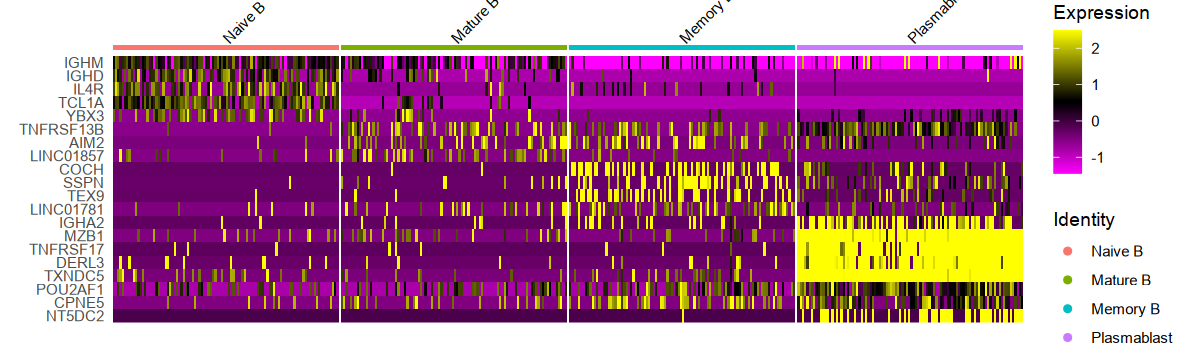

In [58]:
Idents(ft) =  "celltype_level3"

DoHeatmap(subset(ft, downsample = 100), 
          features = features_to_plot, size = 3)